# Notebook Eksperimen — Klasifikasi Penyakit Daun Tomat Berbasis SVM
Fusi fitur piksel mentah, GLCM, HOG, LBP (M1/M2/M3), dengan pemeriksaan robustitas StratifiedGroupKFold.

## 1. Import Library dan Konfigurasi Dasar

In [1]:
from pathlib import Path
import os
import json
import joblib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern

SEED = 42
IMG_SIZE = 128
RAW_PIXEL_SIZE = 32

DATASET_PATH = str(Path.home() / "Documents" / "Skripsi" / "plantvillage_tomato_subset")
OUTPUT_DIR = str(Path.home() / "Documents" / "Skripsi" / "SVM_bertahap")
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASSES = [
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Septoria_leaf_spot",
]
CLASS_LABELS = ["Early Blight", "Healthy", "Late Blight", "Septoria"]

np.random.seed(SEED)
print("Konfigurasi dasar siap. OUTPUT_DIR:", OUTPUT_DIR)

Konfigurasi dasar siap. OUTPUT_DIR: C:\Users\lenovo\Documents\Skripsi\SVM_bertahap


## 2. Memuat Dataset
Memuat seluruh citra beserta labelnya dari direktori dataset, sebelum pembagian data maupun augmentasi apa pun dilakukan.

In [2]:
def load_dataset(dataset_path, classes, img_size=128):
    images, labels = [], []
    for cls_idx, cls_name in enumerate(classes):
        cls_path = Path(dataset_path) / cls_name
        if not cls_path.exists():
            print(f"[WARN] Folder tidak ditemukan: {cls_path}")
            continue
        for img_file in cls_path.iterdir():
            if img_file.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
                continue
            img = cv2.imread(str(img_file))
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (img_size, img_size))
            images.append(img)
            labels.append(cls_idx)
    images = np.array(images, dtype=np.float32) / 255.0
    labels = np.array(labels, dtype=np.int32)
    return images, labels

X, y = load_dataset(DATASET_PATH, CLASSES, IMG_SIZE)
print("Total citra dimuat:", X.shape, "| Total label:", y.shape)

Total citra dimuat: (6271, 128, 128, 3) | Total label: (6271,)


## 3. Eksplorasi Data (EDA)
Memeriksa distribusi kelas, dimensi citra, serta menampilkan contoh citra tiap kelas sebelum data diproses lebih lanjut.

Dimensi larik citra: (6271, 128, 128, 3)
Rentang nilai piksel setelah normalisasi: [0.00, 1.00]

Distribusi kelas:
       Kelas  Jumlah Citra
Early Blight          1000
     Healthy          1591
 Late Blight          1909
    Septoria          1771


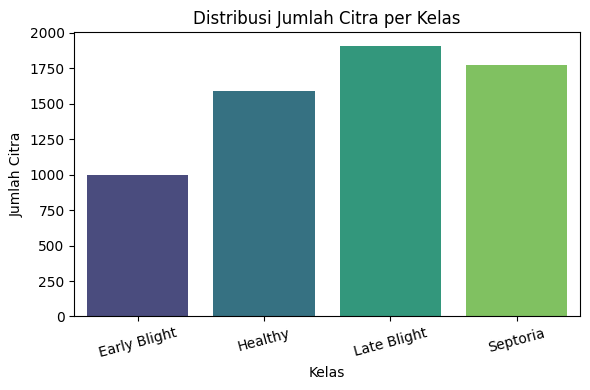

In [3]:
print("Dimensi larik citra:", X.shape)
print("Rentang nilai piksel setelah normalisasi: [{:.2f}, {:.2f}]".format(X.min(), X.max()))

unique, counts = np.unique(y, return_counts=True)
dist_df = pd.DataFrame({"Kelas": [CLASS_LABELS[i] for i in unique], "Jumlah Citra": counts})
print("\nDistribusi kelas:")
print(dist_df.to_string(index=False))

plt.figure(figsize=(6, 4))
sns.barplot(data=dist_df, x="Kelas", y="Jumlah Citra", hue="Kelas", legend=False, palette="viridis")
plt.title("Distribusi Jumlah Citra per Kelas")
plt.ylabel("Jumlah Citra")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "eda_distribusi_kelas.png"), dpi=150)
plt.show()

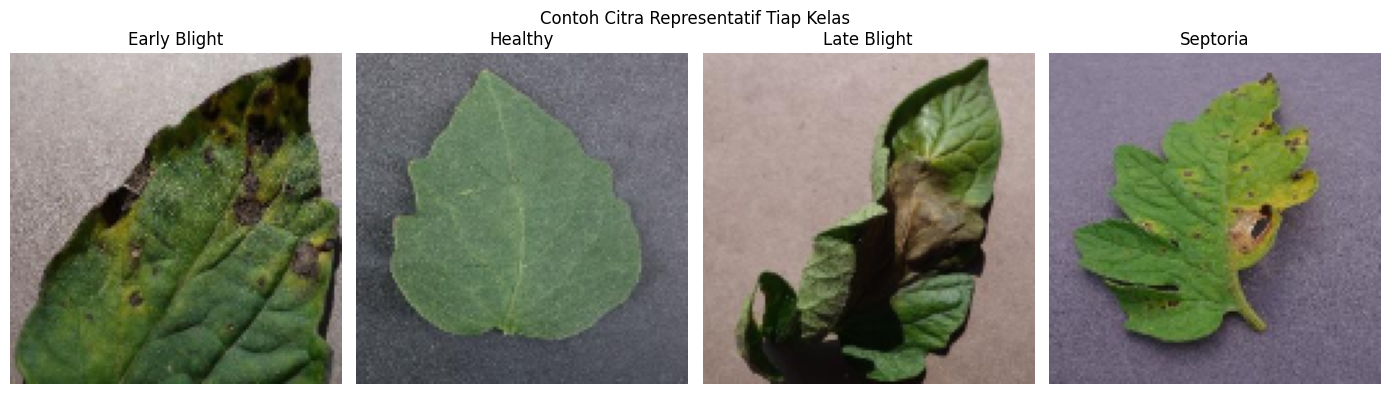

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for cls_idx in range(len(CLASS_LABELS)):
    sample_idx = np.where(y == cls_idx)[0][0]
    axes[cls_idx].imshow(X[sample_idx])
    axes[cls_idx].set_title(CLASS_LABELS[cls_idx])
    axes[cls_idx].axis("off")
plt.suptitle("Contoh Citra Representatif Tiap Kelas")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "eda_contoh_citra.png"), dpi=150)
plt.show()

## 4. Pembagian Data (Train-Test Split)
Membagi dataset menjadi data latih dan data uji secara berstratifikasi, sebelum augmentasi maupun ekstraksi fitur apa pun dilakukan. Data uji dipisahkan sejak tahap ini dan tidak dilibatkan pada augmentasi, pencarian hyperparameter, maupun pelatihan model.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (5016, 128, 128, 3) | Data uji: (1255, 128, 128, 3)


## 5. Augmentasi Fotometrik
Augmentasi kecerahan dan kontras diterapkan khusus pada data latih untuk memperbanyak variasi data latih, tanpa mengubah hubungan spasial antarpiksel.

In [6]:
AUG_CONFIGS = [
    {"type": "normal"},
    {"type": "brightness", "beta": -40},
    {"type": "brightness", "beta": 40},
    {"type": "contrast", "alpha": 0.7},
    {"type": "contrast", "alpha": 1.5},
]

def apply_aug(img_array, config):
    img = (img_array * 255).astype(np.uint8)
    ctype = config["type"]
    if ctype == "normal":
        return img_array
    elif ctype == "brightness":
        result = cv2.convertScaleAbs(img, alpha=1.0, beta=config.get("beta", 0))
    elif ctype == "contrast":
        result = cv2.convertScaleAbs(img, alpha=config.get("alpha", 1.0), beta=0)
    return result.astype(np.float32) / 255.0

augmented = np.empty_like(X_train)
for i, img in enumerate(X_train):
    augmented[i] = apply_aug(img, AUG_CONFIGS[i % len(AUG_CONFIGS)])

X_train_aug = np.concatenate([X_train, augmented], axis=0)
y_train_aug = np.concatenate([y_train, y_train], axis=0)
groups_train_aug = np.concatenate([np.arange(len(X_train)), np.arange(len(X_train))])

perm = np.random.RandomState(SEED).permutation(len(X_train_aug))
X_train_aug = X_train_aug[perm]
y_train_aug = y_train_aug[perm]
groups_train_aug = groups_train_aug[perm]

print("Data latih setelah augmentasi:", X_train_aug.shape)

Data latih setelah augmentasi: (10032, 128, 128, 3)


## 6. Ekstraksi Fitur
Keempat kelompok fitur (piksel mentah, GLCM, HOG, LBP) diekstraksi dari data latih teraugmentasi dan data uji secara terpisah.

In [7]:
def extract_raw_pixels(images, target_size=RAW_PIXEL_SIZE):
    features = []
    for img in images:
        small = cv2.resize(img, (target_size, target_size))
        features.append(small.flatten())
    return np.array(features)

GLCM_DISTANCES = [1, 2, 3]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_PROPS = ["energy", "contrast", "correlation", "homogeneity"]

def extract_glcm_features(images):
    all_features = []
    for img in images:
        gray = cv2.cvtColor((img * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
        gray_q = (gray // 4).astype(np.uint8)
        glcm = graycomatrix(gray_q, distances=GLCM_DISTANCES, angles=GLCM_ANGLES,
                             levels=64, symmetric=True, normed=True)
        features = []
        for d_idx in range(len(GLCM_DISTANCES)):
            for prop in GLCM_PROPS:
                vals = graycoprops(glcm, prop)[d_idx]
                features.extend(vals.tolist())
            for a_idx in range(len(GLCM_ANGLES)):
                p = glcm[:, :, d_idx, a_idx]
                p_nonzero = p[p > 0]
                entropy = -np.sum(p_nonzero * np.log2(p_nonzero))
                features.append(entropy)
        all_features.append(features)
    return np.array(all_features)

HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (32, 32)
HOG_CELLS_PER_BLOCK = (2, 2)

def extract_hog_features(images):
    features = []
    for img in images:
        gray = cv2.cvtColor((img * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
        feat = hog(gray, orientations=HOG_ORIENTATIONS, pixels_per_cell=HOG_PIXELS_PER_CELL,
                   cells_per_block=HOG_CELLS_PER_BLOCK, block_norm="L2-Hys", feature_vector=True)
        features.append(feat)
    return np.array(features)

LBP_P = 8
LBP_R = 1

def extract_lbp_features(images, P=LBP_P, R=LBP_R):
    features = []
    n_bins = P + 2
    for img in images:
        gray = cv2.cvtColor((img * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(gray, P, R, method="uniform")
        hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)
        features.append(hist)
    return np.array(features)

raw_train = extract_raw_pixels(X_train)
raw_train_aug = extract_raw_pixels(X_train_aug)
raw_test = extract_raw_pixels(X_test)

glcm_train = extract_glcm_features(X_train)
glcm_train_aug = extract_glcm_features(X_train_aug)
glcm_test = extract_glcm_features(X_test)

hog_train = extract_hog_features(X_train)
hog_train_aug = extract_hog_features(X_train_aug)
hog_test = extract_hog_features(X_test)

lbp_train = extract_lbp_features(X_train)
lbp_train_aug = extract_lbp_features(X_train_aug)
lbp_test = extract_lbp_features(X_test)

print("Raw:", raw_train_aug.shape, "| GLCM:", glcm_train_aug.shape,
      "| HOG:", hog_train_aug.shape, "| LBP:", lbp_train_aug.shape)

Raw: (10032, 3072) | GLCM: (10032, 60) | HOG: (10032, 324) | LBP: (10032, 10)


## 7. Normalisasi Fitur dengan Robust Scaler
Parameter penskalaan dihitung dari data latih sebelum augmentasi, kemudian diterapkan secara konsisten pada data latih teraugmentasi dan data uji.

In [8]:
raw_scaler = RobustScaler().fit(raw_train)
glcm_scaler = RobustScaler().fit(glcm_train)
hog_scaler = RobustScaler().fit(hog_train)
lbp_scaler = RobustScaler().fit(lbp_train)

raw_aug_n = raw_scaler.transform(raw_train_aug)
raw_test_n = raw_scaler.transform(raw_test)

glcm_aug_n = glcm_scaler.transform(glcm_train_aug)
glcm_test_n = glcm_scaler.transform(glcm_test)

hog_aug_n = hog_scaler.transform(hog_train_aug)
hog_test_n = hog_scaler.transform(hog_test)

lbp_aug_n = lbp_scaler.transform(lbp_train_aug)
lbp_test_n = lbp_scaler.transform(lbp_test)

print("Normalisasi selesai")

Normalisasi selesai


## 8. Konstruksi Konfigurasi Fitur (M1, M2, M3)
Ketiga konfigurasi fitur disusun secara kumulatif lewat concatenation.

In [9]:
feature_sets = {
    "M1_Raw": (raw_aug_n, raw_test_n),
    "M2_Raw_GLCM": (
        np.concatenate([raw_aug_n, glcm_aug_n], axis=1),
        np.concatenate([raw_test_n, glcm_test_n], axis=1),
    ),
    "M3_Raw_GLCM_HOG_LBP": (
        np.concatenate([raw_aug_n, glcm_aug_n, hog_aug_n, lbp_aug_n], axis=1),
        np.concatenate([raw_test_n, glcm_test_n, hog_test_n, lbp_test_n], axis=1),
    ),
}

model_names = list(feature_sets.keys())
for name, (train_feat, test_feat) in feature_sets.items():
    print(name, train_feat.shape, test_feat.shape)

M1_Raw (10032, 3072) (1255, 3072)
M2_Raw_GLCM (10032, 3132) (1255, 3132)
M3_Raw_GLCM_HOG_LBP (10032, 3466) (1255, 3466)


## 9. Pencarian Hyperparameter (GridSearchCV + StratifiedGroupKFold)
Pencarian kombinasi C dan gamma terbaik dilakukan lewat validasi silang berkelompok pada data latih, menjamin seluruh varian augmentasi dari satu citra asli tetap berada pada partisi yang sama.

In [10]:
PARAM_GRID = {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.001]}
GROUP_CV_3 = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

best_params = {}
for name, (train_feat, _) in feature_sets.items():
    grid = GridSearchCV(
        SVC(kernel="rbf", random_state=SEED), PARAM_GRID,
        cv=GROUP_CV_3, scoring="accuracy", n_jobs=-1,
    )
    grid.fit(train_feat, y_train_aug, groups=groups_train_aug)
    best_params[name] = grid.best_params_
    print(f"{name:24s} Best params: {grid.best_params_}  CV Acc: {grid.best_score_*100:.2f}%")

M1_Raw                   Best params: {'C': 10, 'gamma': 'scale'}  CV Acc: 84.39%
M2_Raw_GLCM              Best params: {'C': 10, 'gamma': 'scale'}  CV Acc: 86.58%
M3_Raw_GLCM_HOG_LBP      Best params: {'C': 10, 'gamma': 'scale'}  CV Acc: 89.49%


## 10. Pelatihan Model dan Evaluasi Holdout
Ketiga konfigurasi dilatih menggunakan hyperparameter optimalnya masing-masing, lalu dievaluasi pada data uji yang belum pernah dilibatkan dalam proses sebelumnya. Akurasi pada data latih turut dihitung sebagai pemeriksaan selisih (gap check) terhadap indikasi overfitting.

In [11]:
def evaluate_svm(feat_train, feat_test, y_train, y_test, name, params):
    clf = SVC(kernel="rbf", random_state=SEED, probability=True, **params)
    clf.fit(feat_train, y_train)

    train_preds = clf.predict(feat_train)
    preds = clf.predict(feat_test)

    train_acc = accuracy_score(y_train, train_preds)
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average="macro")

    return {
        "model": name, "clf": clf, "preds": preds,
        "train_accuracy": train_acc,
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1,
        "best_params": params,
    }

holdout_results = {}
for name, (train_feat, test_feat) in feature_sets.items():
    holdout_results[name] = evaluate_svm(
        train_feat, test_feat, y_train_aug, y_test, name, best_params[name]
    )
    r = holdout_results[name]
    gap = abs(r["train_accuracy"] - r["accuracy"]) * 100
    print(f"{r['model']:24s} Train Acc: {r['train_accuracy']*100:.2f}%  Test Acc: {r['accuracy']*100:.2f}%  "
          f"Gap: {gap:.2f} poin  |  Prec: {r['precision']*100:.2f}%  Rec: {r['recall']*100:.2f}%  F1: {r['f1']*100:.2f}%")

M1_Raw                   Train Acc: 99.96%  Test Acc: 88.45%  Gap: 11.51 poin  |  Prec: 87.26%  Rec: 86.67%  F1: 86.93%
M2_Raw_GLCM              Train Acc: 99.96%  Test Acc: 90.36%  Gap: 9.60 poin  |  Prec: 89.28%  Rec: 88.86%  F1: 89.04%
M3_Raw_GLCM_HOG_LBP      Train Acc: 99.96%  Test Acc: 92.35%  Gap: 7.61 poin  |  Prec: 91.68%  Rec: 90.71%  F1: 91.12%


## 11. Laporan Klasifikasi per Kelas

In [12]:
classification_reports = {}
for name, r in holdout_results.items():
    report = classification_report(y_test, r["preds"], target_names=CLASS_LABELS,
                                    output_dict=True, zero_division=0)
    classification_reports[name] = report
    print(f"--- {name} ---")
    print(classification_report(y_test, r["preds"], target_names=CLASS_LABELS, zero_division=0))

--- M1_Raw ---
              precision    recall  f1-score   support

Early Blight       0.77      0.70      0.73       200
     Healthy       0.95      0.95      0.95       318
 Late Blight       0.85      0.88      0.87       382
    Septoria       0.92      0.93      0.92       355

    accuracy                           0.88      1255
   macro avg       0.87      0.87      0.87      1255
weighted avg       0.88      0.88      0.88      1255

--- M2_Raw_GLCM ---
              precision    recall  f1-score   support

Early Blight       0.80      0.74      0.77       200
     Healthy       0.98      1.00      0.99       318
 Late Blight       0.87      0.88      0.88       382
    Septoria       0.93      0.94      0.93       355

    accuracy                           0.90      1255
   macro avg       0.89      0.89      0.89      1255
weighted avg       0.90      0.90      0.90      1255

--- M3_Raw_GLCM_HOG_LBP ---
              precision    recall  f1-score   support

Early Blight

## 12. Visualisasi Confusion Matrix

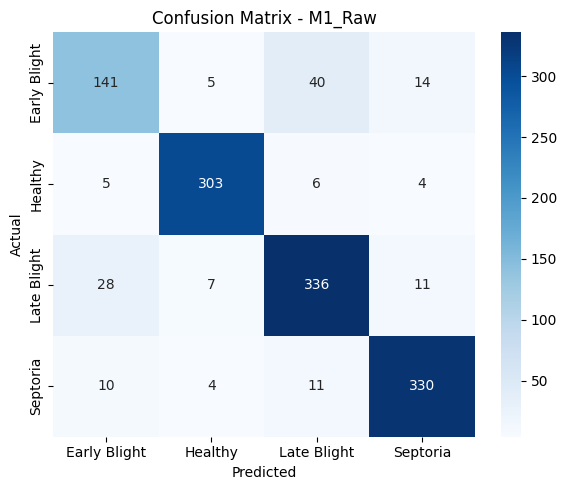

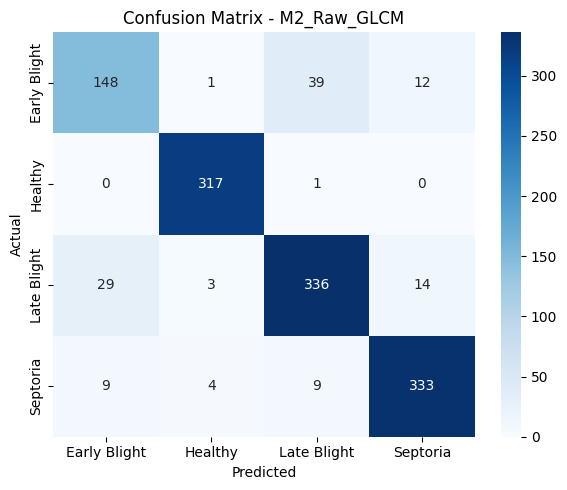

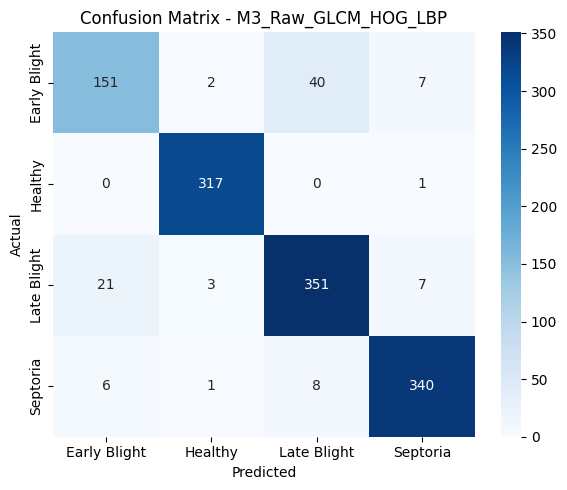

In [13]:
for name, r in holdout_results.items():
    cm = confusion_matrix(y_test, r["preds"])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_LABELS,
                yticklabels=CLASS_LABELS, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    filepath = os.path.join(OUTPUT_DIR, f"confusion_matrix_{name}.png")
    plt.savefig(filepath, dpi=150)
    plt.show()
    plt.close(fig)

## 13. Visualisasi HOG (Sebelum dan Sesudah)

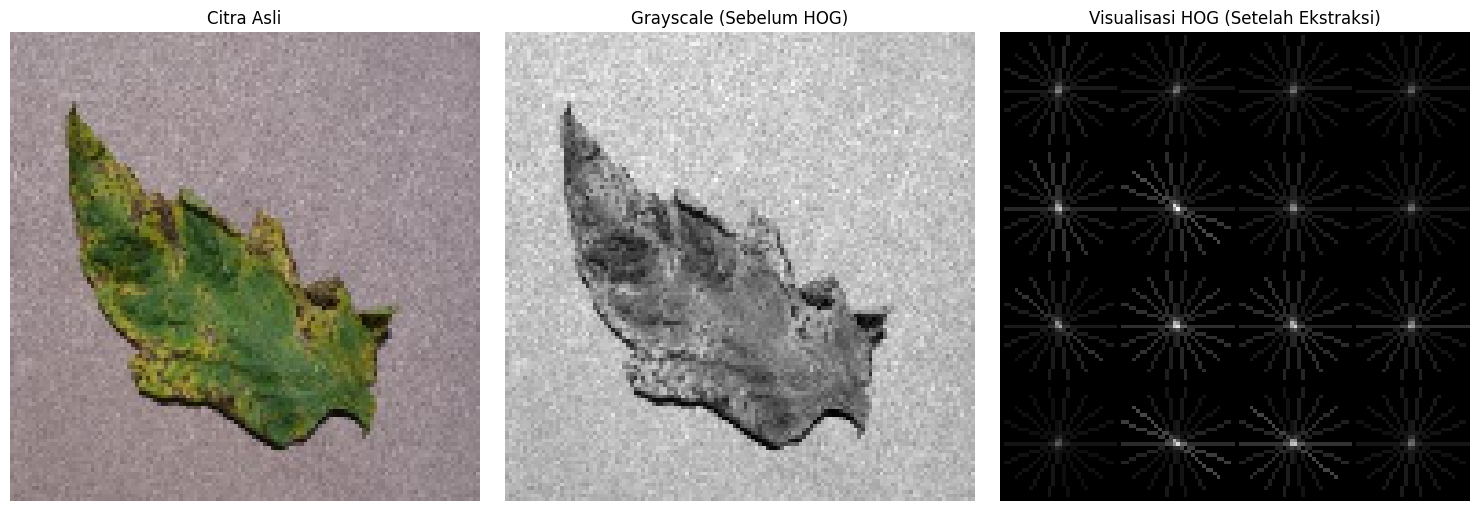

In [14]:
sample_idx = np.random.RandomState(SEED).choice(len(X_train), size=1)[0]
sample_img = X_train[sample_idx]
sample_gray = cv2.cvtColor((sample_img * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)

_, hog_image = hog(sample_gray, orientations=HOG_ORIENTATIONS, pixels_per_cell=HOG_PIXELS_PER_CELL,
                    cells_per_block=HOG_CELLS_PER_BLOCK, block_norm="L2-Hys",
                    visualize=True, feature_vector=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_img)
axes[0].set_title("Citra Asli")
axes[0].axis("off")

axes[1].imshow(sample_gray, cmap="gray")
axes[1].set_title("Grayscale (Sebelum HOG)")
axes[1].axis("off")

axes[2].imshow(hog_image, cmap="gray")
axes[2].set_title("Visualisasi HOG (Setelah Ekstraksi)")
axes[2].axis("off")

plt.tight_layout()
filepath = os.path.join(OUTPUT_DIR, "hog_before_after.png")
plt.savefig(filepath, dpi=150)
plt.show()
plt.close(fig)

## 14. Visualisasi LBP (Sebelum dan Sesudah)

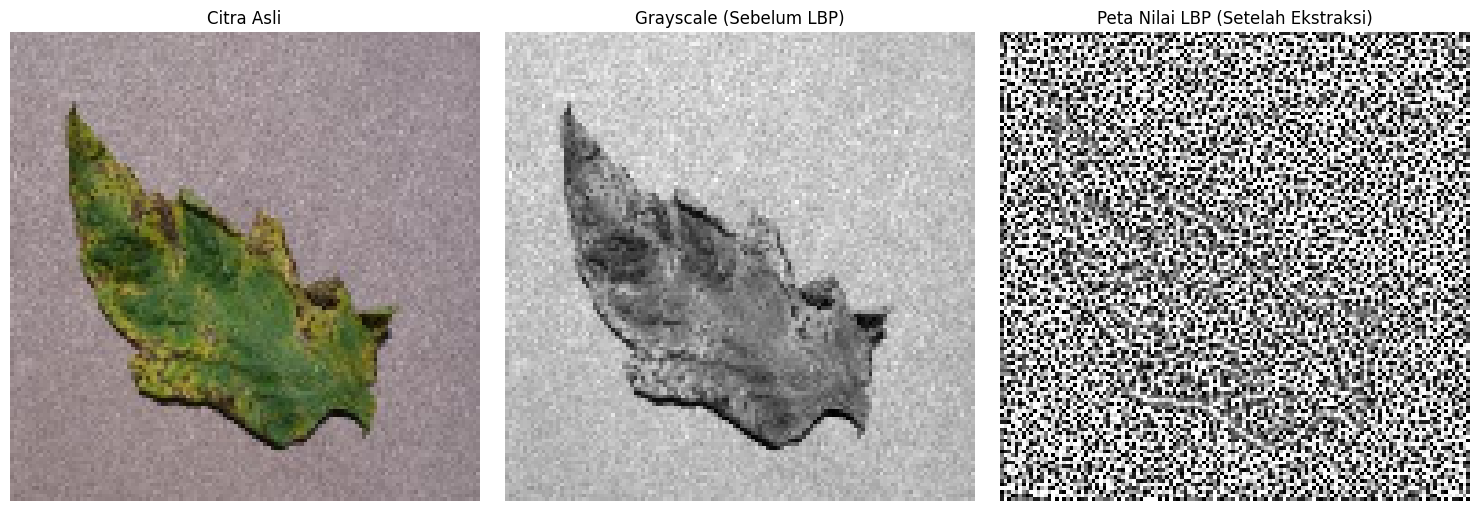

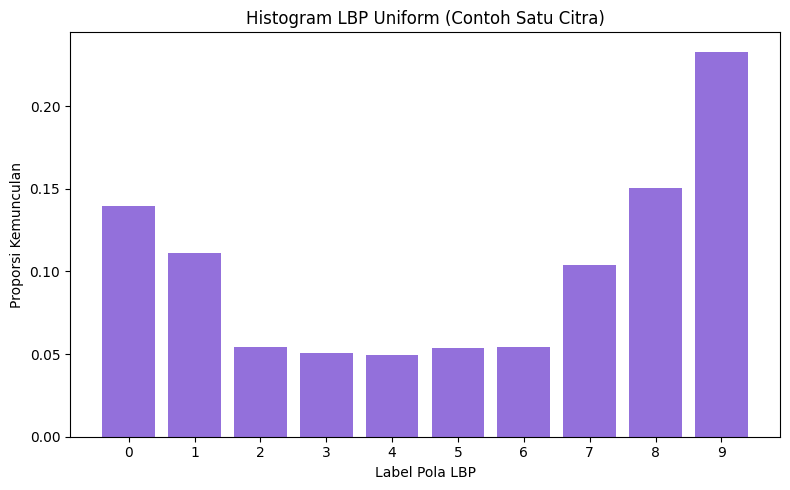

In [15]:
lbp_image = local_binary_pattern(sample_gray, LBP_P, LBP_R, method="uniform")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_img)
axes[0].set_title("Citra Asli")
axes[0].axis("off")

axes[1].imshow(sample_gray, cmap="gray")
axes[1].set_title("Grayscale (Sebelum LBP)")
axes[1].axis("off")

axes[2].imshow(lbp_image, cmap="gray")
axes[2].set_title("Peta Nilai LBP (Setelah Ekstraksi)")
axes[2].axis("off")

plt.tight_layout()
filepath = os.path.join(OUTPUT_DIR, "lbp_before_after.png")
plt.savefig(filepath, dpi=150)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
n_bins = LBP_P + 2
hist_vals, _ = np.histogram(lbp_image, bins=n_bins, range=(0, n_bins), density=True)
ax.bar(range(n_bins), hist_vals, color="mediumpurple")
ax.set_xlabel("Label Pola LBP")
ax.set_ylabel("Proporsi Kemunculan")
ax.set_title("Histogram LBP Uniform (Contoh Satu Citra)")
ax.set_xticks(range(n_bins))
plt.tight_layout()
filepath = os.path.join(OUTPUT_DIR, "lbp_histogram_example.png")
plt.savefig(filepath, dpi=150)
plt.show()
plt.close(fig)

## 15. Ringkasan Grafik Batang Seluruh Metrik

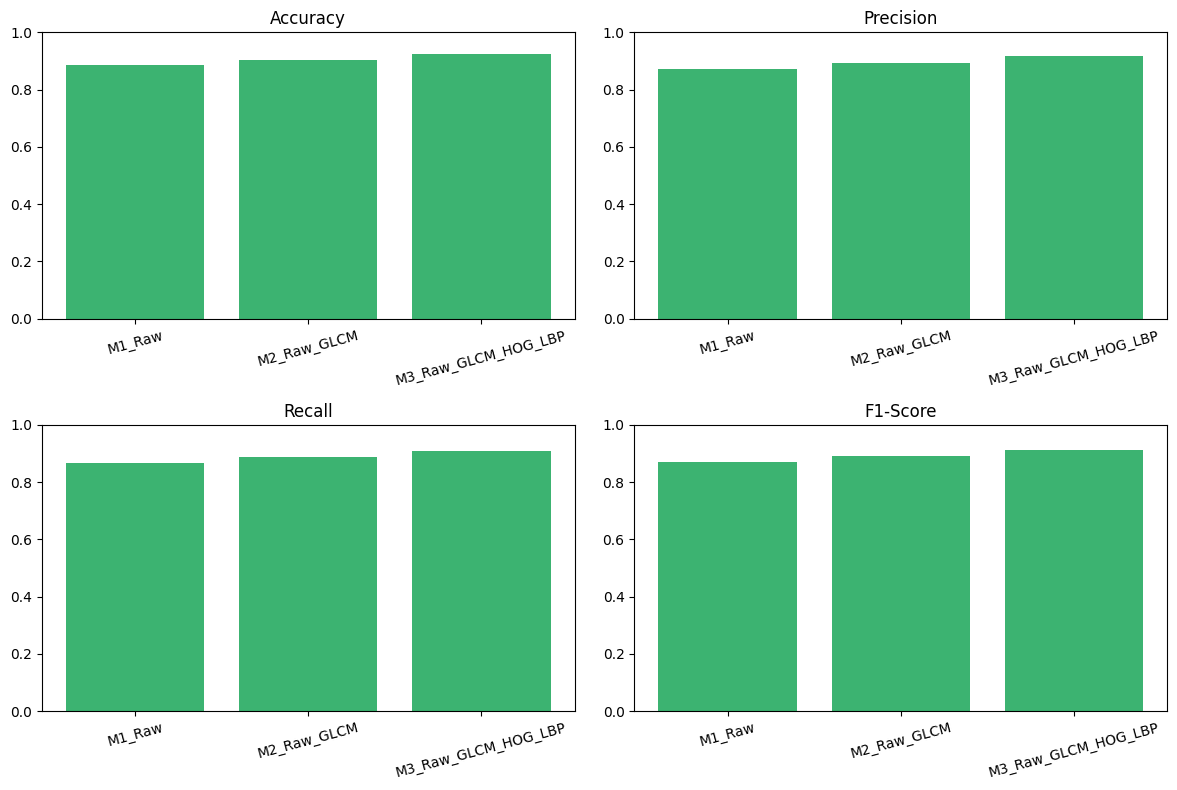

In [16]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1-Score"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for idx, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
    values = [holdout_results[n][metric] for n in model_names]
    axes[idx].bar(model_names, values, color="mediumseagreen")
    axes[idx].set_title(label)
    axes[idx].set_ylim(0, 1)
    axes[idx].tick_params(axis="x", rotation=15)

plt.tight_layout()
filepath = os.path.join(OUTPUT_DIR, "summary_all_metrics.png")
plt.savefig(filepath, dpi=150)
plt.show()
plt.close(fig)

## 16. Pemeriksaan Robustitas — Repeated StratifiedGroupKFold
Mengatasi keterbatasan "satu kali split" dengan mengevaluasi tiap konfigurasi fitur pada tiga pembagian data latih-uji yang berbeda, menggunakan StratifiedGroupKFold yang konsisten dengan metode yang sudah diterapkan pada pencarian hyperparameter. Hyperparameter terbaik yang sudah ditemukan sebelumnya (Subbab 9) dipakai ulang di sini, sehingga pemeriksaan ini tidak perlu mengulang GridSearchCV. Hasil holdout utama pada Subbab 10 tetap menjadi acuan pelaporan utama; bagian ini murni sebagai bukti pendukung stabilitas hasil.

In [17]:
N_OUTER_SPLITS = 3
outer_cv = StratifiedGroupKFold(n_splits=N_OUTER_SPLITS, shuffle=True, random_state=SEED)
original_groups = np.arange(len(X))

robustness_results = {name: {"accuracy": [], "precision": [], "recall": [], "f1": []} for name in model_names}

for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups=original_groups)):
    X_tr_fold, X_te_fold = X[train_idx], X[test_idx]
    y_tr_fold, y_te_fold = y[train_idx], y[test_idx]

    augmented_fold = np.empty_like(X_tr_fold)
    for i, img in enumerate(X_tr_fold):
        augmented_fold[i] = apply_aug(img, AUG_CONFIGS[i % len(AUG_CONFIGS)])
    X_tr_fold_aug = np.concatenate([X_tr_fold, augmented_fold], axis=0)
    y_tr_fold_aug = np.concatenate([y_tr_fold, y_tr_fold], axis=0)

    raw_tr_f = extract_raw_pixels(X_tr_fold)
    raw_tr_aug_f = extract_raw_pixels(X_tr_fold_aug)
    raw_te_f = extract_raw_pixels(X_te_fold)
    glcm_tr_f = extract_glcm_features(X_tr_fold)
    glcm_tr_aug_f = extract_glcm_features(X_tr_fold_aug)
    glcm_te_f = extract_glcm_features(X_te_fold)
    hog_tr_f = extract_hog_features(X_tr_fold)
    hog_tr_aug_f = extract_hog_features(X_tr_fold_aug)
    hog_te_f = extract_hog_features(X_te_fold)
    lbp_tr_f = extract_lbp_features(X_tr_fold)
    lbp_tr_aug_f = extract_lbp_features(X_tr_fold_aug)
    lbp_te_f = extract_lbp_features(X_te_fold)

    raw_scaler_f = RobustScaler().fit(raw_tr_f)
    glcm_scaler_f = RobustScaler().fit(glcm_tr_f)
    hog_scaler_f = RobustScaler().fit(hog_tr_f)
    lbp_scaler_f = RobustScaler().fit(lbp_tr_f)

    raw_tr_n_f = raw_scaler_f.transform(raw_tr_aug_f); raw_te_n_f = raw_scaler_f.transform(raw_te_f)
    glcm_tr_n_f = glcm_scaler_f.transform(glcm_tr_aug_f); glcm_te_n_f = glcm_scaler_f.transform(glcm_te_f)
    hog_tr_n_f = hog_scaler_f.transform(hog_tr_aug_f); hog_te_n_f = hog_scaler_f.transform(hog_te_f)
    lbp_tr_n_f = lbp_scaler_f.transform(lbp_tr_aug_f); lbp_te_n_f = lbp_scaler_f.transform(lbp_te_f)

    feature_sets_fold = {
        "M1_Raw": (raw_tr_n_f, raw_te_n_f),
        "M2_Raw_GLCM": (
            np.concatenate([raw_tr_n_f, glcm_tr_n_f], axis=1),
            np.concatenate([raw_te_n_f, glcm_te_n_f], axis=1),
        ),
        "M3_Raw_GLCM_HOG_LBP": (
            np.concatenate([raw_tr_n_f, glcm_tr_n_f, hog_tr_n_f, lbp_tr_n_f], axis=1),
            np.concatenate([raw_te_n_f, glcm_te_n_f, hog_te_n_f, lbp_te_n_f], axis=1),
        ),
    }

    for name, (feat_tr, feat_te) in feature_sets_fold.items():
        clf_f = SVC(kernel="rbf", random_state=SEED, probability=True, **best_params[name])
        clf_f.fit(feat_tr, y_tr_fold_aug)
        preds_f = clf_f.predict(feat_te)
        acc_f = accuracy_score(y_te_fold, preds_f)
        prec_f, rec_f, f1_f, _ = precision_recall_fscore_support(y_te_fold, preds_f, average="macro")
        robustness_results[name]["accuracy"].append(acc_f)
        robustness_results[name]["precision"].append(prec_f)
        robustness_results[name]["recall"].append(rec_f)
        robustness_results[name]["f1"].append(f1_f)

    print(f"Partisi luar {fold_idx+1}/{N_OUTER_SPLITS} selesai")

print()
for name in model_names:
    accs = np.array(robustness_results[name]["accuracy"]) * 100
    precs = np.array(robustness_results[name]["precision"]) * 100
    recs = np.array(robustness_results[name]["recall"]) * 100
    f1s = np.array(robustness_results[name]["f1"]) * 100
    print(f"{name:24s} Acc: {accs.mean():.2f}% +/- {accs.std():.2f}%  "
          f"Prec: {precs.mean():.2f}% +/- {precs.std():.2f}%  "
          f"Rec: {recs.mean():.2f}% +/- {recs.std():.2f}%  "
          f"F1: {f1s.mean():.2f}% +/- {f1s.std():.2f}%")

Partisi luar 1/3 selesai
Partisi luar 2/3 selesai
Partisi luar 3/3 selesai

M1_Raw                   Acc: 87.07% +/- 1.10%  Prec: 85.77% +/- 1.12%  Rec: 85.73% +/- 1.14%  F1: 85.74% +/- 1.12%
M2_Raw_GLCM              Acc: 88.85% +/- 0.63%  Prec: 87.52% +/- 0.73%  Rec: 87.55% +/- 0.65%  F1: 87.53% +/- 0.68%
M3_Raw_GLCM_HOG_LBP      Acc: 91.13% +/- 0.36%  Prec: 90.17% +/- 0.58%  Rec: 90.12% +/- 0.27%  F1: 90.12% +/- 0.37%


## 17. Ekspor Modul Ekstraksi Fitur
Modul ini disalin ke aplikasi antarmuka agar logika ekstraksi fitur identik antara notebook eksperimen dan aplikasi.

In [18]:
feature_utils_code = '''
import cv2
import numpy as np
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern

def preprocess_image(image_bgr, img_size):
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_resized = cv2.resize(image_rgb, (img_size, img_size))
    return image_resized.astype(np.float32) / 255.0

def extract_raw_pixel_features(image_float, target_size):
    small = cv2.resize(image_float, (target_size, target_size))
    return small.flatten().reshape(1, -1)

def extract_glcm_features(image_float, distances, angles, props):
    gray = cv2.cvtColor((image_float * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    gray_q = (gray // 4).astype(np.uint8)
    glcm = graycomatrix(gray_q, distances=distances, angles=angles,
                         levels=64, symmetric=True, normed=True)
    features = []
    for d_idx in range(len(distances)):
        for prop in props:
            vals = graycoprops(glcm, prop)[d_idx]
            features.extend(vals.tolist())
        for a_idx in range(len(angles)):
            p = glcm[:, :, d_idx, a_idx]
            p_nonzero = p[p > 0]
            entropy = -np.sum(p_nonzero * np.log2(p_nonzero))
            features.append(entropy)
    return np.array(features).reshape(1, -1)

def extract_hog_features(image_float, orientations, pixels_per_cell, cells_per_block):
    gray = cv2.cvtColor((image_float * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    feat = hog(gray, orientations=orientations, pixels_per_cell=tuple(pixels_per_cell),
               cells_per_block=tuple(cells_per_block), block_norm="L2-Hys", feature_vector=True)
    return feat.reshape(1, -1)

def extract_lbp_features(image_float, p, r):
    gray = cv2.cvtColor((image_float * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, p, r, method="uniform")
    n_bins = p + 2
    hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)
    return hist.reshape(1, -1)
'''

with open(os.path.join(OUTPUT_DIR, "feature_utils.py"), "w", encoding="utf-8") as f:
    f.write(feature_utils_code)

print("feature_utils.py tersimpan di", OUTPUT_DIR)

feature_utils.py tersimpan di C:\Users\lenovo\Documents\Skripsi\SVM_bertahap


## 18. Ekspor Artefak
Model, scaler, konfigurasi fitur, dan seluruh hasil evaluasi (termasuk hasil robustitas) disimpan sebagai berkas, siap dimuat oleh aplikasi antarmuka.

In [19]:
for name, r in holdout_results.items():
    joblib.dump(r["clf"], os.path.join(OUTPUT_DIR, f"svm_{name.lower()}.pkl"))

joblib.dump(raw_scaler, os.path.join(OUTPUT_DIR, "raw_scaler.pkl"))
joblib.dump(glcm_scaler, os.path.join(OUTPUT_DIR, "glcm_scaler.pkl"))
joblib.dump(hog_scaler, os.path.join(OUTPUT_DIR, "hog_scaler.pkl"))
joblib.dump(lbp_scaler, os.path.join(OUTPUT_DIR, "lbp_scaler.pkl"))

feature_config = {
    "img_size": IMG_SIZE,
    "raw_pixel_size": RAW_PIXEL_SIZE,
    "glcm_distances": GLCM_DISTANCES,
    "glcm_angles": [float(a) for a in GLCM_ANGLES],
    "glcm_props": GLCM_PROPS,
    "hog_orientations": HOG_ORIENTATIONS,
    "hog_pixels_per_cell": list(HOG_PIXELS_PER_CELL),
    "hog_cells_per_block": list(HOG_CELLS_PER_BLOCK),
    "lbp_p": LBP_P,
    "lbp_r": LBP_R,
    "classes": CLASSES,
    "class_names": CLASS_LABELS,
    "best_params": best_params,
}
with open(os.path.join(OUTPUT_DIR, "feature_config.json"), "w", encoding="utf-8") as f:
    json.dump(feature_config, f, indent=2)

holdout_df = pd.DataFrame([
    {"model": name, **{k: v for k, v in r.items() if k not in ["clf", "preds", "best_params"]}}
    for name, r in holdout_results.items()
])
holdout_df.to_csv(os.path.join(OUTPUT_DIR, "holdout_results.csv"), index=False)

classification_report_rows = []
for name, report in classification_reports.items():
    for class_label, metrics in report.items():
        if isinstance(metrics, dict):
            classification_report_rows.append({"model": name, "class": class_label, **metrics})
pd.DataFrame(classification_report_rows).to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv"), index=False)

robustness_rows = []
for name, metrics in robustness_results.items():
    for fold_i in range(N_OUTER_SPLITS):
        robustness_rows.append({
            "model": name, "fold": fold_i + 1,
            "accuracy": metrics["accuracy"][fold_i],
            "precision": metrics["precision"][fold_i],
            "recall": metrics["recall"][fold_i],
            "f1": metrics["f1"][fold_i],
        })
pd.DataFrame(robustness_rows).to_csv(
    os.path.join(OUTPUT_DIR, "robustness_check_results.csv"), index=False)

print("Seluruh artefak dan hasil tersimpan di", OUTPUT_DIR)

Seluruh artefak dan hasil tersimpan di C:\Users\lenovo\Documents\Skripsi\SVM_bertahap
